In [1]:
print("Hello, Red Wine Quality Project!")

Hello, Red Wine Quality Project!


In [2]:
print("teste funcionando!")

teste funcionando!


# Prédiction de la qualité des vins rouges par Machine Learning

## Présentation du projet

Ce projet vise à prédire la qualité des vins rouges
à partir de leurs caractéristiques physico-chimiques.

Nous utilisons le jeu de données Wine Quality (UCI)
et comparons trois modèles de régression :
la régression linéaire, le Random Forest
et le Gradient Boosting.

L'étude comprend l'exploration des données,
l'entraînement des modèles, leur évaluation,
l'optimisation des hyperparamètres
et l'interprétation des résultats.

In [3]:
import pandas as pd

df = pd.read_csv("../data/winequality-red.csv", sep=";")

df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [4]:
df.shape

(1599, 12)

## 1. Exploration initiale des données

Cette étape consiste à examiner la structure du jeu de données,
les types de variables et la présence éventuelle de valeurs manquantes.

In [5]:
# Informations générales sur le jeu de données
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [6]:
# Vérification des valeurs manquantes
df.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

### Premières observations

Le jeu de données contient 1 599 observations et 12 variables :
11 caractéristiques physico-chimiques et une variable cible (`quality`).

Toutes les variables sont numériques et aucune valeur manquante
n'a été détectée.

Aucune imputation des données manquantes n'est donc nécessaire.

In [7]:
# Statistiques descriptives des variables
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


### Analyse des statistiques descriptives

La variable cible `quality` présente une moyenne de 5,64,
une médiane de 6 et un écart-type d'environ 0,81.

Les notes observées varient de 3 à 8, avec une concentration
importante entre 5 et 6.

Les variables physico-chimiques présentent des échelles
différentes. Certaines variables, notamment `residual sugar`
et `total sulfur dioxide`, montrent des valeurs maximales
élevées par rapport à leur moyenne.

Ces observations seront prises en compte lors du choix
des modèles et des étapes de prétraitement.

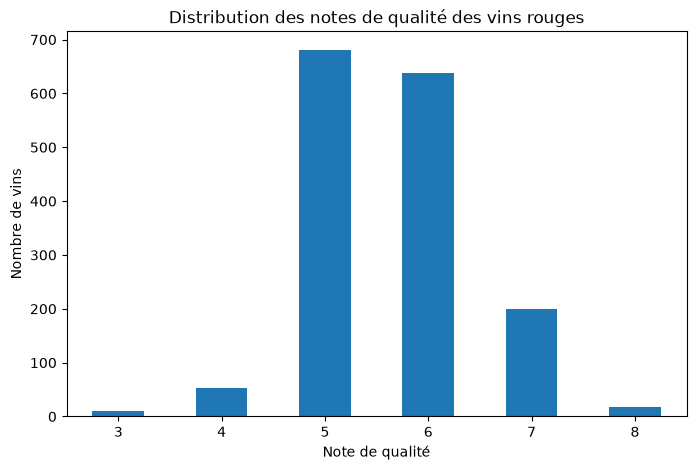

In [8]:
import matplotlib.pyplot as plt

# Distribution des notes de qualité
df["quality"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Distribution des notes de qualité des vins rouges")
plt.xlabel("Note de qualité")
plt.ylabel("Nombre de vins")
plt.xticks(rotation=0)
plt.show()

### Interprétation de la distribution

La distribution des notes de qualité est fortement concentrée
autour des valeurs 5 et 6, qui représentent environ 82,6 %
des observations.

Les notes extrêmes (3, 4 et 8) sont beaucoup moins fréquentes.

Cette distribution déséquilibrée peut rendre la prédiction
des qualités extrêmes plus difficile pour les modèles de régression.

Il sera donc important d'évaluer les erreurs de prédiction,
notamment pour les vins de faible et de haute qualité.

In [9]:
# Corrélation entre les variables et la qualité
correlations = df.corr()["quality"].sort_values(ascending=False)

print(correlations)

quality                 1.000000
alcohol                 0.476166
sulphates               0.251397
citric acid             0.226373
fixed acidity           0.124052
residual sugar          0.013732
free sulfur dioxide    -0.050656
pH                     -0.057731
chlorides              -0.128907
density                -0.174919
total sulfur dioxide   -0.185100
volatile acidity       -0.390558
Name: quality, dtype: float64


### Interprétation des corrélations

L'analyse des corrélations de Pearson montre que :

- `alcohol` présente la corrélation positive la plus élevée
  avec la qualité (r = 0,476).
- `volatile acidity` présente la corrélation négative
  la plus importante (r = -0,391).
- `sulphates` et `citric acid` présentent des
  corrélations positives plus faibles.
- `residual sugar` ne présente pratiquement aucune
  corrélation linéaire avec la qualité.

Ces résultats suggèrent que certaines caractéristiques
physico-chimiques sont associées aux notes de qualité.

Cependant, une corrélation ne démontre pas une relation
de causalité et ne permet pas, à elle seule, d'évaluer
l'importance prédictive d'une variable.

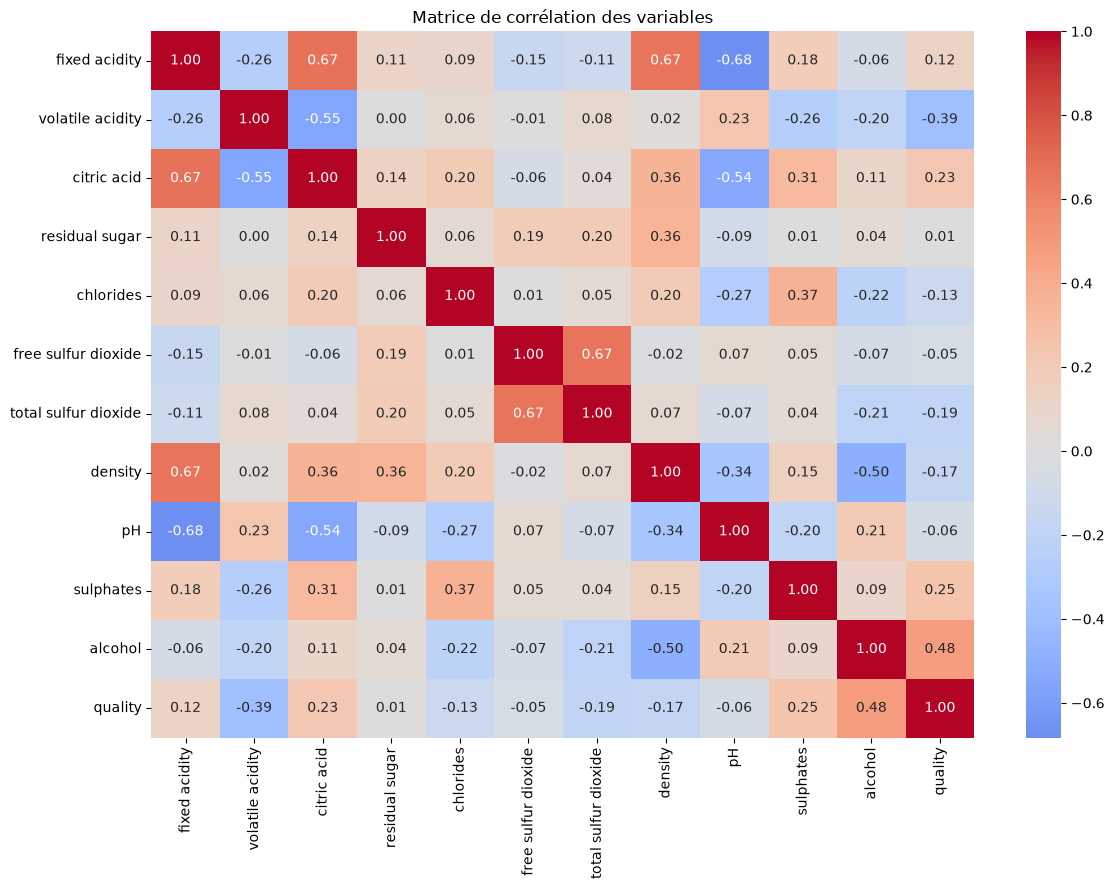

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Matrice de corrélation
matrice_corr = df.corr()

# Visualisation de la matrice
plt.figure(figsize=(12, 9))

sns.heatmap(
    matrice_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Matrice de corrélation des variables")
plt.tight_layout()
plt.show()

### Interprétation de la matrice de corrélation

La matrice de corrélation met en évidence plusieurs relations
entre les caractéristiques physico-chimiques des vins.

Les corrélations les plus importantes avec la qualité sont
observées pour `alcohol` (r = 0,48) et
`volatile acidity` (r = -0,39).

Certaines variables explicatives sont également corrélées
entre elles, notamment :

- `fixed acidity` et `pH` : r = -0,68 ;
- `fixed acidity` et `citric acid` : r = 0,67 ;
- `free sulfur dioxide` et `total sulfur dioxide` : r = 0,67.

Ces relations peuvent entraîner des problèmes de
multicolinéarité, notamment pour l'interprétation
des coefficients d'une régression linéaire.

Dans un premier temps, toutes les variables explicatives
seront conservées pour entraîner les modèles.

## 2. Préparation des données pour la régression

Nous séparons les variables explicatives (X) de la
variable cible (y), correspondant à la qualité du vin.

In [11]:
# Séparation des variables explicatives et de la cible
X = df.drop(columns=["quality"])
y = df["quality"]

# Vérification des dimensions
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Dimensions de X : (1599, 11)
Dimensions de y : (1599,)


### Séparation des données d'entraînement et de test

Le jeu de données est divisé en deux ensembles :

- 80 % pour l'entraînement des modèles ;
- 20 % pour leur évaluation finale.

Cette séparation permet d'évaluer la capacité des modèles
à généraliser leurs prédictions à de nouvelles observations.

In [12]:
from sklearn.model_selection import train_test_split

# Séparation des données : 80 % entraînement, 20 % test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Vérification des dimensions
print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

X_train : (1279, 11)
X_test  : (320, 11)
y_train : (1279,)
y_test  : (320,)


## 3. Entraînement des modèles

### 3.1 Régression linéaire

La régression linéaire est utilisée comme premier modèle
de référence (baseline).

Elle cherche à établir une relation linéaire entre les
caractéristiques physico-chimiques et la qualité du vin.

In [13]:
from sklearn.linear_model import LinearRegression

# Création du modèle de régression linéaire
modele_lineaire = LinearRegression()

# Entraînement sur les données d'apprentissage
modele_lineaire.fit(X_train, y_train)

# Prédictions sur les données de test
y_pred_lineaire = modele_lineaire.predict(X_test)

# Affichage des premières prédictions
print("Prédictions :", y_pred_lineaire[:10])
print("Valeurs réelles :", y_test.iloc[:10].values)

Prédictions : [5.34666441 5.05631345 5.66446972 5.46451484 5.72518476 5.27928659
 5.03421667 5.12623347 5.74534288 5.68665032]
Valeurs réelles : [6 5 6 5 6 5 5 5 5 6]


### 3.2 Évaluation de la régression linéaire

Nous évaluons les performances du modèle à l'aide de
trois métriques : MAE, RMSE et R².

Ces métriques permettront de comparer la régression linéaire
aux autres modèles étudiés.

In [14]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calcul des métriques de la régression linéaire
mae_lineaire = mean_absolute_error(y_test, y_pred_lineaire)
rmse_lineaire = np.sqrt(mean_squared_error(y_test, y_pred_lineaire))
r2_lineaire = r2_score(y_test, y_pred_lineaire)

# Affichage des résultats
print(f"MAE  : {mae_lineaire:.4f}")
print(f"RMSE : {rmse_lineaire:.4f}")
print(f"R²   : {r2_lineaire:.4f}")

MAE  : 0.5035
RMSE : 0.6245
R²   : 0.4032


### 3.2.1 Interprétation des résultats de la régression linéaire

Le modèle de régression linéaire obtient les performances suivantes sur l'ensemble de test :

- **MAE = 0,5035** : les prédictions s'écartent des notes réelles d'environ 0,50 point en moyenne.
- **RMSE = 0,6245** : cette métrique pénalise davantage les erreurs de prédiction importants.
- **R² = 0,4032** : le modèle explique environ 40,3 % de la variabilité des notes de qualité sur l'ensemble de test.

Ces résultats montrent que la régression linéaire permet de prédire partiellement la qualité des vins à partir de leurs caractéristiques physico-chimiques.

Cependant, les performances restent limitées. Les relations entre les caractéristiques des vins et leur qualité peuvent être complexes et non linéaires, ce qui n'est pas entièrement pris en compte par ce modèle.

**Conclusion :** la régression linéaire constitue un premier modèle de référence (*baseline*). Nous allons maintenant entraîner des modèles plus complexes, notamment **Random Forest** et **Gradient Boosting**, afin de déterminer s'ils permettent d'améliorer les performances prédictives.

### 3.3 Random Forest Regressor

Le Random Forest est un modèle d'apprentissage supervisé
basé sur un ensemble d'arbres de décision.

Il permet de modéliser des relations non linéaires entre
les caractéristiques physico-chimiques et la qualité du vin.

In [15]:
from sklearn.ensemble import RandomForestRegressor

# Création du modèle Random Forest
modele_rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Entraînement du modèle
modele_rf.fit(X_train, y_train)

# Prédictions sur les données de test
y_pred_rf = modele_rf.predict(X_test)

# Affichage des premières prédictions
print("Prédictions :", y_pred_rf[:10])
print("Valeurs réelles :", y_test.iloc[:10].values)

Prédictions : [5.3  5.23 5.46 5.19 6.   5.06 5.13 4.92 6.14 5.87]
Valeurs réelles : [6 5 6 5 6 5 5 5 5 6]


### 3.4 Évaluation du Random Forest Regressor

Nous évaluons les performances du Random Forest à l'aide des mêmes
métriques que pour la régression linéaire : MAE, RMSE et R².

L'objectif est de déterminer si ce modèle, capable d'apprendre
des relations non linéaires, améliore les performances prédictives.

In [16]:
# Calcul des métriques du Random Forest
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

# Affichage des résultats
print(f"MAE  : {mae_rf:.4f}")
print(f"RMSE : {rmse_rf:.4f}")
print(f"R²   : {r2_rf:.4f}")

MAE  : 0.4224
RMSE : 0.5489
R²   : 0.5390


### 3.4.1 Interprétation des résultats du Random Forest

Le modèle Random Forest Regressor obtient les performances suivantes sur l'ensemble de test :

- **MAE = 0,4224** : les prédictions présentent une erreur absolue moyenne d'environ 0,42 point.
- **RMSE = 0,5489** : les erreurs quadratiques sont plus faibles que celles obtenues avec la régression linéaire.
- **R² = 0,5390** : le modèle explique environ 53,9 % de la variabilité des notes de qualité sur l'ensemble de test.

#### Comparaison avec la régression linéaire

| Métrique | Régression linéaire | Random Forest |
|---|---|---|
| MAE | 0,5035 | **0,4224** |
| RMSE | 0,6245 | **0,5489** |
| R² | 0,4032 | **0,5390** |

Le Random Forest améliore les performances sur les trois métriques :

- Réduction du MAE d'environ **16,1 %**.
- Réduction du RMSE d'environ **12,1 %**.
- Augmentation du R² de **0,4032 à 0,5390**.

Ces résultats suggèrent que le Random Forest est mieux adapté à ce jeu de données que la régression linéaire, dans cette première comparaison.

Sa capacité à modéliser des relations non linéaires et des interactions entre variables pourrait contribuer à cette amélioration.

**Conclusion :** le Random Forest présente les meilleures performances parmi les deux modèles évalués jusqu'à présent. Une validation croisée sur les données d'entraînement sera toutefois nécessaire pour comparer les modèles de manière plus rigoureuse.

### 3.5 Gradient Boosting Regressor

Le Gradient Boosting est un algorithme d'apprentissage supervisé
basé sur un ensemble d'arbres de décision construits
séquentiellement.

Contrairement au Random Forest, qui combine des arbres
entraînés de manière relativement indépendante, le Gradient
Boosting construit chaque nouvel arbre pour corriger les
erreurs résiduelles du modèle précédent.

Cette méthode permet de modéliser des relations non linéaires
et des interactions complexes entre les variables.

L'objectif est d'évaluer si le Gradient Boosting permet
d'améliorer les prédictions de la qualité des vins par
rapport à la régression linéaire et au Random Forest.

In [17]:
from sklearn.ensemble import GradientBoostingRegressor

# Création du modèle Gradient Boosting
modele_gb = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Entraînement du modèle
modele_gb.fit(X_train, y_train)

# Prédictions sur les données de test
y_pred_gb = modele_gb.predict(X_test)

# Affichage des premières prédictions
print("Prédictions :", y_pred_gb[:10])
print("Valeurs réelles :", y_test.iloc[:10].values)

Prédictions : [5.34164696 5.02253239 5.27830831 5.28468346 5.77887998 5.11920908
 5.18376144 5.16781189 5.8130402  5.83079071]
Valeurs réelles : [6 5 6 5 6 5 5 5 5 6]


### 3.6 Évaluation du Gradient Boosting Regressor

Nous évaluons les performances du Gradient Boosting à l'aide
des trois métriques utilisées précédemment : MAE, RMSE et R².

L'objectif est de comparer ses performances à celles de la
régression linéaire et du Random Forest.

Cette première évaluation permettra d'observer si le
Gradient Boosting améliore la précision des prédictions.

In [18]:
# Calcul des métriques du Gradient Boosting
mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
r2_gb = r2_score(y_test, y_pred_gb)

# Affichage des résultats
print(f"MAE  : {mae_gb:.4f}")
print(f"RMSE : {rmse_gb:.4f}")
print(f"R²   : {r2_gb:.4f}")

MAE  : 0.4849
RMSE : 0.6019
R²   : 0.4456


### 3.6.1 Interprétation des résultats du Gradient Boosting

Le modèle Gradient Boosting Regressor obtient les performances suivantes sur l'ensemble de test :

- **MAE = 0,4849** : les prédictions présentent une erreur absolue moyenne d'environ 0,48 point.
- **RMSE = 0,6019** : les erreurs de prédiction sont légèrement inférieures à celles de la régression linéaire.
- **R² = 0,4456** : le modèle explique environ 44,6 % de la variabilité des notes de qualité sur l'ensemble de test.

#### Comparaison avec les modèles précédents

| Métrique | Régression linéaire | Random Forest | Gradient Boosting |
|---|---|---|---|
| MAE | 0,5035 | **0,4224** | 0,4849 |
| RMSE | 0,6245 | **0,5489** | 0,6019 |
| R² | 0,4032 | **0,5390** | 0,4456 |

Le Gradient Boosting améliore légèrement les performances de la régression linéaire, mais reste moins performant que le Random Forest dans cette première évaluation.

Le Random Forest présente actuellement les meilleurs résultats sur les trois métriques.

Cependant, les modèles ont été entraînés avec des hyperparamètres initiaux, sans optimisation systématique.

**Conclusion :** une validation croisée et une optimisation des hyperparamètres seront nécessaires afin de comparer les modèles plus rigoureusement et d'améliorer leurs performances.

## 4. Validation croisée des modèles

La validation croisée (*cross-validation*) permet d'évaluer
la capacité de généralisation des modèles en utilisant
plusieurs partitions des données d'entraînement.

Nous utilisons une validation croisée à **5 folds (K = 5)**.

À chaque itération :
- 4 folds sont utilisés pour entraîner le modèle ;
- 1 fold est utilisé pour la validation.

Le processus est répété cinq fois, en changeant le fold
de validation à chaque itération.

L'objectif est de comparer les performances et la stabilité
des trois modèles : régression linéaire, Random Forest
et Gradient Boosting.

**Important :** l'ensemble de test est exclu de cette étape
afin d'éviter toute fuite d'information (*data leakage*).

In [19]:
from sklearn.model_selection import KFold, cross_val_score
import numpy as np

# Définition de la validation croisée à 5 folds
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Modèles à comparer
modeles = {
    "Régression linéaire": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

# Validation croisée avec la métrique MAE
for nom, modele in modeles.items():

    scores = cross_val_score(
        modele,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    mae_scores = -scores

    print(f"\n{nom}")
    print(f"MAE par fold : {np.round(mae_scores, 4)}")
    print(f"MAE moyen    : {mae_scores.mean():.4f}")
    print(f"Écart-type   : {mae_scores.std():.4f}")


Régression linéaire
MAE par fold : [0.4832 0.4905 0.5172 0.5052 0.5325]
MAE moyen    : 0.5057
Écart-type   : 0.0178

Random Forest
MAE par fold : [0.4084 0.4085 0.4471 0.4302 0.4606]
MAE moyen    : 0.4310
Écart-type   : 0.0207

Gradient Boosting
MAE par fold : [0.4636 0.4594 0.4875 0.4864 0.5019]
MAE moyen    : 0.4798
Écart-type   : 0.0159


### 4.1 Interprétation des résultats de la validation croisée

La validation croisée à 5 folds a permis d'évaluer les
performances et la stabilité des trois modèles sur
l'ensemble d'entraînement.

Les résultats obtenus sont les suivants :

| Modèle | MAE moyen | Écart-type |
|---|---|---|
| Régression linéaire | 0,5057 | 0,0178 |
| Random Forest | **0,4310** | 0,0207 |
| Gradient Boosting | 0,4798 | **0,0159** |

#### Analyse des performances

Le **Random Forest** obtient le MAE moyen le plus faible
(0,4310), ce qui confirme les résultats encourageants
observés lors de la première évaluation.

Le **Gradient Boosting** présente un MAE moyen de 0,4798.
Il améliore les performances de la régression linéaire,
mais reste moins performant que le Random Forest.

La **régression linéaire** présente le MAE moyen le plus
élevé (0,5057).

#### Analyse de la stabilité

L'écart-type permet d'observer la variabilité des
performances entre les différents folds.

Le Gradient Boosting présente l'écart-type le plus faible
(0,0159), suivi de la régression linéaire (0,0178)
et du Random Forest (0,0207).

Les performances des trois modèles restent relativement
stables entre les cinq folds.

#### Conclusion

Le Random Forest constitue actuellement le modèle le plus
prometteur pour prédire la qualité des vins rouges.

Une optimisation des hyperparamètres sera réalisée afin
d'améliorer ses performances prédictives.

## 5. Optimisation des hyperparamètres

Après avoir comparé les trois modèles par validation croisée,
nous allons optimiser les hyperparamètres du Random Forest.

Le Random Forest a obtenu le MAE moyen le plus faible lors
de la validation croisée à 5 folds.

Nous utiliserons la méthode **GridSearchCV**, qui permet
d'évaluer plusieurs combinaisons d'hyperparamètres afin
d'identifier la configuration offrant les meilleures
performances.

L'optimisation sera réalisée exclusivement sur les données
d'entraînement, sans utiliser l'ensemble de test.

In [20]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor

# Définition des hyperparamètres à tester
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

# Création du modèle
rf = RandomForestRegressor(random_state=42)

# Recherche des meilleurs hyperparamètres
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    verbose=1
)

# Entraînement et optimisation
grid_search.fit(X_train, y_train)

# Affichage des résultats
print("Meilleurs hyperparamètres :")
print(grid_search.best_params_)

print("\nMeilleur MAE moyen :")
print(f"{-grid_search.best_score_:.4f}")

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Meilleurs hyperparamètres :
{'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}

Meilleur MAE moyen :
0.4308


### 5.1 Résultats de l'optimisation du Random Forest

La méthode GridSearchCV a évalué 24 combinaisons
d'hyperparamètres à l'aide d'une validation croisée
à 5 folds, soit 120 entraînements au total.

Les meilleurs hyperparamètres identifiés sont :

- **n_estimators :** 100
- **max_depth :** 20
- **min_samples_split :** 2
- **min_samples_leaf :** 1

Le meilleur MAE moyen obtenu est de **0,4308**.

#### Comparaison avant et après optimisation

| Modèle | MAE moyen |
|---|---|
| Random Forest initial | 0,4310 |
| Random Forest optimisé | **0,4308** |

L'optimisation permet une amélioration très légère
du MAE moyen, d'environ 0,05 %.

Cette faible différence suggère que les hyperparamètres
initiaux étaient déjà adaptés au jeu de données,
parmi les configurations étudiées.

La principale modification concerne la profondeur
maximale des arbres, limitée à 20.

#### Conclusion

L'optimisation des hyperparamètres n'apporte pas
d'amélioration significative des performances
observées.

Le Random Forest reste le modèle le plus prometteur
parmi les trois algorithmes étudiés.

Il est important de noter que le meilleur score obtenu
par GridSearchCV est un score de sélection, et non
une estimation indépendante des performances finales.

In [21]:
# Récupération du meilleur modèle Random Forest
meilleur_rf = grid_search.best_estimator_

# Affichage du modèle optimisé
print(meilleur_rf)

RandomForestRegressor(max_depth=20, random_state=42)


## 6. Interprétation du modèle : importance des variables

Après l'optimisation des hyperparamètres, nous analysons
l'importance des variables explicatives dans le modèle
Random Forest.

Cette analyse permet d'identifier les caractéristiques
physico-chimiques qui contribuent le plus aux prédictions
de la qualité des vins rouges.

Nous utilisons dans un premier temps l'attribut
`feature_importances_` du Random Forest, qui mesure
l'importance relative des variables à partir de la
réduction de l'impureté dans les arbres.

L'objectif est de mieux comprendre le fonctionnement
du modèle et d'identifier les variables les plus influentes
sur ses prédictions.

Cette mesure ne permet toutefois pas d'établir
des relations causales.

                Variable  Importance
10               alcohol    0.270976
9              sulphates    0.148429
1       volatile acidity    0.111568
6   total sulfur dioxide    0.077013
4              chlorides    0.070612
8                     pH    0.061713
3         residual sugar    0.057897
0          fixed acidity    0.053110
2            citric acid    0.050978
7                density    0.050696
5    free sulfur dioxide    0.047008


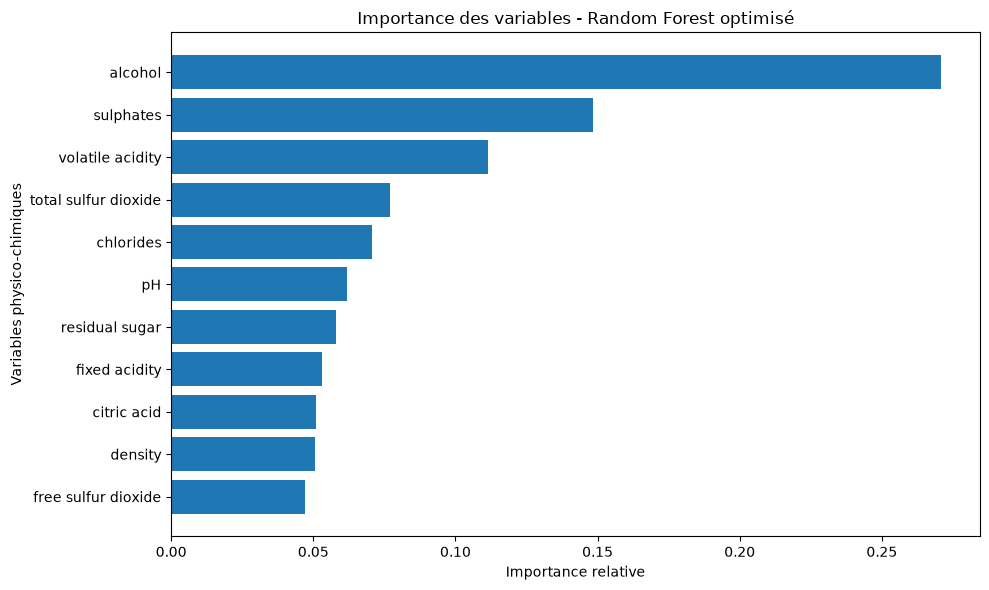

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

# Extraction de l'importance des variables
importances = meilleur_rf.feature_importances_

# Création d'un DataFrame
df_importances = pd.DataFrame({
    "Variable": X_train.columns,
    "Importance": importances
})

# Classement des variables par importance
df_importances = df_importances.sort_values(
    by="Importance",
    ascending=False
)

# Affichage des résultats
print(df_importances)

# Visualisation graphique
plt.figure(figsize=(10, 6))

plt.barh(
    df_importances["Variable"],
    df_importances["Importance"]
)

plt.gca().invert_yaxis()

plt.xlabel("Importance relative")
plt.ylabel("Variables physico-chimiques")
plt.title("Importance des variables - Random Forest optimisé")

plt.tight_layout()
plt.show()

### 6.1 Interprétation de l'importance des variables

L'analyse de l'importance des variables du Random Forest
optimisé permet d'identifier les caractéristiques
physico-chimiques les plus utilisées par le modèle.

Les trois variables les plus importantes sont :

1. **Alcohol (27,10 %)**
2. **Sulphates (14,84 %)**
3. **Volatile acidity (11,16 %)**

Ces trois variables représentent ensemble environ
53,1 % de l'importance totale calculée par le modèle.

#### Comparaison avec l'analyse exploratoire

Lors de l'analyse exploratoire, nous avions observé
les corrélations suivantes avec la qualité du vin :

- Alcohol : +0,476
- Volatile acidity : -0,391
- Sulphates : +0,251

Ces trois variables apparaissent également parmi les
plus importantes du Random Forest.

Cependant, la corrélation et l'importance des variables
ne mesurent pas la même chose.

La corrélation mesure l'association linéaire entre
deux variables, tandis que l'importance calculée par
le Random Forest mesure la contribution des variables
à la réduction de l'impureté dans les arbres.

De plus, l'importance ne permet pas de déterminer
le sens de l'influence d'une variable ni d'établir
une relation causale.

#### Conclusion

Le degré d'alcool, les sulfates et l'acidité volatile
jouent un rôle particulièrement important dans les
prédictions du Random Forest.

Ces résultats sont cohérents avec certaines observations
de l'analyse exploratoire.

Une analyse complémentaire par permutation importance
permettra de vérifier ces résultats à l'aide d'une
méthode différente.

### 6.2 Importance des variables par permutation

Afin de compléter l'analyse précédente, nous utilisons
la méthode de permutation importance.

Cette méthode consiste à mélanger aléatoirement les
valeurs d'une variable et à mesurer la dégradation
des performances du modèle.

Une augmentation importante de l'erreur après
permutation indique que le modèle dépend fortement
de cette variable pour réaliser ses prédictions.

L'analyse sera réalisée sur une partition de validation
issue des données d'entraînement, afin de préserver
l'ensemble de test pour l'évaluation finale.

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from sklearn.base import clone

# Création d'un ensemble de validation interne
X_train_perm, X_val_perm, y_train_perm, y_val_perm = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42
)

# Entraînement d'une copie du modèle optimisé
modele_perm = clone(meilleur_rf)
modele_perm.fit(X_train_perm, y_train_perm)

# Calcul de l'importance par permutation
resultat_perm = permutation_importance(
    modele_perm,
    X_val_perm,
    y_val_perm,
    n_repeats=10,
    random_state=42,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

# Création du tableau des résultats
df_perm = pd.DataFrame({
    "Variable": X_train.columns,
    "Importance moyenne": resultat_perm.importances_mean,
    "Écart-type": resultat_perm.importances_std
})

# Classement des variables
df_perm = df_perm.sort_values(
    by="Importance moyenne",
    ascending=False
)

print(df_perm)

                Variable  Importance moyenne  Écart-type
10               alcohol            0.143811    0.012516
9              sulphates            0.100180    0.012459
1       volatile acidity            0.045462    0.007890
6   total sulfur dioxide            0.035539    0.008130
7                density            0.022347    0.004005
8                     pH            0.016434    0.003859
0          fixed acidity            0.015320    0.003759
2            citric acid            0.015255    0.002630
5    free sulfur dioxide            0.015001    0.002694
4              chlorides            0.014576    0.001865
3         residual sugar            0.013993    0.003486


### 6.2.1 Interprétation des résultats de la permutation importance

L'analyse par permutation importance permet de mesurer
la contribution des variables aux performances prédictives
du Random Forest.

Les trois variables les plus importantes sont :

1. **Alcohol : 0,1438**
2. **Sulphates : 0,1002**
3. **Volatile acidity : 0,0455**

Ces valeurs représentent l'augmentation moyenne du MAE
lorsque les valeurs de chaque variable sont mélangées
aléatoirement.

Par exemple, la permutation de la variable `alcohol`
entraîne une augmentation moyenne du MAE d'environ
0,144 point.

Cela indique que le modèle dépend fortement de cette
variable pour réaliser ses prédictions.

#### Comparaison avec l'importance par réduction d'impureté

Les deux méthodes identifient les mêmes trois variables
principales, dans le même ordre :

- Alcohol
- Sulphates
- Volatile acidity

Cette cohérence renforce l'interprétation des résultats.

Cependant, certaines variables changent de position
selon la méthode utilisée. Par exemple, `density`
passe de la dixième à la cinquième position.

Ces différences s'expliquent notamment par les
principes de calcul propres à chaque méthode.

#### Limites de l'interprétation

L'importance des variables ne permet pas d'établir
une relation de causalité.

De plus, la présence de variables corrélées peut
influencer les résultats de la permutation importance.

#### Conclusion

Les analyses suggèrent que le degré d'alcool,
les sulfates et l'acidité volatile sont les variables
les plus importantes pour les prédictions du
Random Forest optimisé.

Les résultats obtenus par les deux méthodes sont
globalement cohérents.

## 7. Évaluation finale du modèle sélectionné

Après la comparaison des différents algorithmes,
la validation croisée et l'optimisation des
hyperparamètres, nous retenons le Random Forest
comme modèle final.

Nous évaluons ses performances à l'aide des métriques
MAE, RMSE et R².

Nous analyserons également la relation entre les
valeurs réelles et les valeurs prédites, ainsi que
la distribution des erreurs.

L'ensemble de test a déjà été consulté lors des
comparaisons exploratoires. Les résultats présentés
ici doivent donc être interprétés en tenant compte
de cette limite méthodologique.

In [24]:
# Prédictions du Random Forest optimisé
y_pred_final = meilleur_rf.predict(X_test)

# Calcul des métriques
mae_final = mean_absolute_error(y_test, y_pred_final)
rmse_final = np.sqrt(mean_squared_error(y_test, y_pred_final))
r2_final = r2_score(y_test, y_pred_final)

# Affichage des résultats
print("Random Forest optimisé - Évaluation finale")
print(f"MAE  : {mae_final:.4f}")
print(f"RMSE : {rmse_final:.4f}")
print(f"R²   : {r2_final:.4f}")

Random Forest optimisé - Évaluation finale
MAE  : 0.4224
RMSE : 0.5487
R²   : 0.5392


### 7.1 Interprétation des résultats de l'évaluation finale

Le Random Forest optimisé obtient les performances suivantes
sur l'ensemble de test :

- **MAE = 0,4224**
- **RMSE = 0,5487**
- **R² = 0,5392**

Le modèle présente une erreur absolue moyenne d'environ
0,42 point sur l'échelle de qualité des vins.

Le coefficient de détermination indique que le modèle
explique environ 53,9 % de la variabilité des notes
sur l'ensemble de test.

#### Comparaison avant et après optimisation

| Métrique | Random Forest initial | Random Forest optimisé |
|---|---|---|
| MAE | 0,4224 | 0,4224 |
| RMSE | 0,5489 | 0,5487 |
| R² | 0,5390 | 0,5392 |

L'optimisation des hyperparamètres apporte une amélioration
très légère des performances.

Les résultats montrent que la configuration initiale
du Random Forest était déjà relativement adaptée
au jeu de données.

Cependant, une partie importante de la variabilité
des notes reste inexpliquée.

De plus, l'ensemble de test ayant déjà été consulté
lors des comparaisons exploratoires, ces résultats
ne constituent pas une évaluation entièrement indépendante.

**Conclusion :** le Random Forest optimisé reste le
modèle retenu pour la prédiction de la qualité des vins
rouges, avec des performances satisfaisantes mais
encore perfectibles.

### 7.2 Visualisation des valeurs réelles et prédites

Afin d'analyser les performances du modèle, nous
représentons graphiquement les valeurs réelles
et les valeurs prédites de la qualité des vins.

La ligne diagonale représente les prédictions parfaites,
pour lesquelles la valeur prédite est égale à la
valeur réelle.

Plus les points sont proches de cette ligne,
plus les prédictions sont précises.

Cette visualisation permet également d'identifier
d'éventuels biais ou erreurs systématiques du modèle.

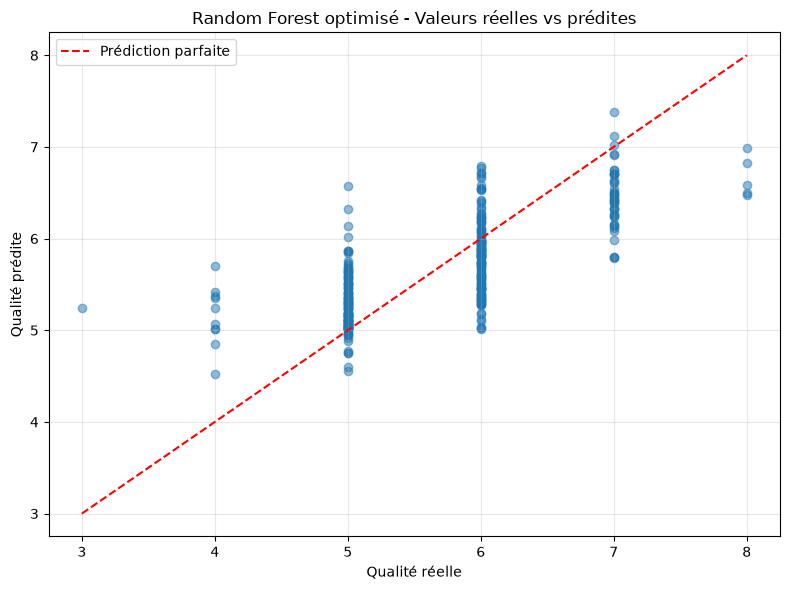

In [25]:
import matplotlib.pyplot as plt

# Visualisation des valeurs réelles et prédites
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_final,
    alpha=0.5
)

# Ligne représentant les prédictions parfaites
plt.plot(
    [3, 8],
    [3, 8],
    color="red",
    linestyle="--",
    label="Prédiction parfaite"
)

plt.xlabel("Qualité réelle")
plt.ylabel("Qualité prédite")
plt.title("Random Forest optimisé - Valeurs réelles vs prédites")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 7.2.1 Interprétation du graphique des valeurs réelles et prédites

Le graphique compare les notes réelles des vins aux
prédictions du Random Forest optimisé.

La ligne diagonale rouge représente les prédictions
parfaites, pour lesquelles la valeur prédite est égale
à la valeur réelle.

#### Principales observations

**1. Vins de faible qualité (notes 3 et 4)**

Le modèle a tendance à surestimer leur qualité.

Par exemple, un vin ayant une note réelle de 3
obtient une prédiction proche de 5,2.

**2. Vins de qualité intermédiaire (notes 5 et 6)**

Les prédictions sont globalement plus proches des
valeurs réelles, même si une certaine dispersion
reste observable.

**3. Vins de qualité élevée (notes 7 et 8)**

Le modèle a tendance à sous-estimer leur qualité.

Les vins ayant une note réelle de 8 reçoivent
des prédictions situées approximativement entre
6,5 et 7.

#### Explication possible

Ces résultats peuvent notamment s'expliquer par
la distribution déséquilibrée de la variable cible.

Environ 82,6 % des vins du jeu de données possèdent
une note de 5 ou 6.

Le modèle apprend donc principalement les
caractéristiques des vins de qualité intermédiaire.

Cela peut entraîner une concentration des prédictions
autour des valeurs centrales, un phénomène proche
de la régression vers la moyenne.

#### Conclusion

Le Random Forest présente des performances
satisfaisantes pour les vins de qualité intermédiaire,
mais rencontre davantage de difficultés pour prédire
les notes extrêmes.

Cette limite doit être prise en compte dans
l'interprétation des performances du modèle.

### 7.3 Analyse des résidus

L'analyse des résidus permet d'étudier les erreurs
commises par le modèle.

Un résidu correspond à la différence entre la valeur
réelle et la valeur prédite :

$$
e_i = y_i - \hat{y}_i
$$

Un résidu positif indique que le modèle sous-estime
la qualité du vin.

Un résidu négatif indique que le modèle surestime
la qualité du vin.

L'objectif est d'observer la distribution des erreurs
et d'identifier d'éventuelles tendances systématiques.

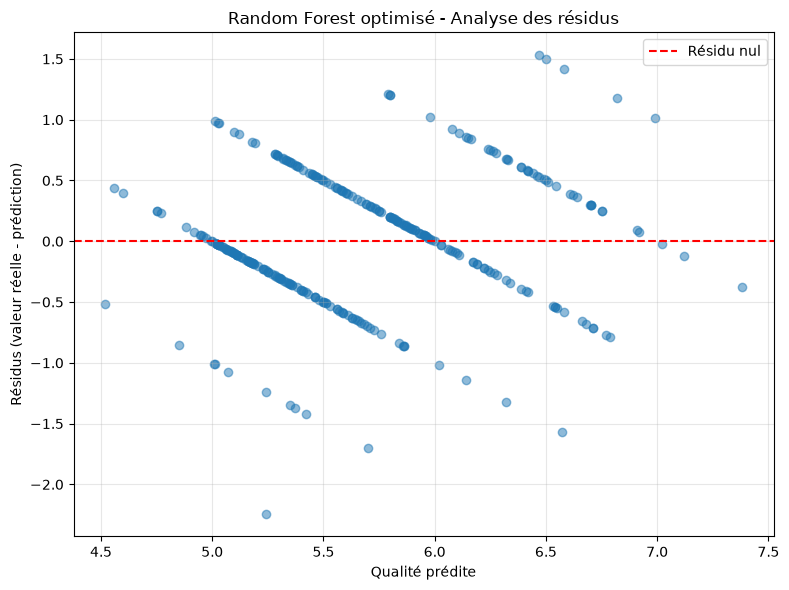

In [26]:
# Calcul des résidus
residus = y_test - y_pred_final

# Visualisation des résidus en fonction des prédictions
plt.figure(figsize=(8, 6))

plt.scatter(
    y_pred_final,
    residus,
    alpha=0.5
)

# Ligne horizontale correspondant à une erreur nulle
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Résidu nul"
)

plt.xlabel("Qualité prédite")
plt.ylabel("Résidus (valeur réelle - prédiction)")
plt.title("Random Forest optimisé - Analyse des résidus")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 7.3.1 Interprétation de l'analyse des résidus

Le graphique représente les résidus en fonction des
valeurs prédites par le Random Forest optimisé.

Les résidus sont calculés selon la formule :

$$
e_i = y_i - \hat{y}_i
$$

#### Principales observations

Les résidus présentent des valeurs positives et
négatives, ce qui indique que le modèle peut
sous-estimer ou surestimer la qualité des vins.

Une partie importante des résidus se situe
relativement près de zéro, mais certaines
observations présentent des erreurs plus élevées.

Le graphique présente également plusieurs
bandes diagonales parallèles.

Ce phénomène s'explique par la nature discrète
de la variable cible `quality`, qui prend des
valeurs entières, tandis que les prédictions
du modèle sont continues.

Pour une valeur réelle fixe, les résidus suivent
la relation :

$$
e = y - \hat{y}
$$

Ces bandes diagonales sont donc attendues et
ne constituent pas une erreur de programmation.

#### Limites du modèle

L'analyse confirme que le modèle présente
certaines difficultés pour prédire les
notes extrêmes.

Il tend notamment à surestimer les vins de
faible qualité et à sous-estimer ceux de
qualité élevée.

#### Conclusion

L'analyse des résidus met en évidence des
performances prédictives globalement raisonnables,
mais également certaines erreurs importantes.

Ces observations sont cohérentes avec les
résultats des métriques MAE, RMSE et R²
ainsi qu'avec le graphique des valeurs
réelles et prédites.

### 7.4 Analyse quantitative des erreurs

Afin de compléter l'analyse graphique des résidus,
nous calculons plusieurs statistiques descriptives.

Nous étudions notamment :

- La moyenne et l'écart-type des résidus.
- Les erreurs minimale et maximale.
- La proportion des prédictions dont l'erreur
  absolue est inférieure ou égale à 0,5 point.
- La proportion des prédictions dont l'erreur
  absolue est inférieure ou égale à 1 point.

Ces indicateurs permettent de mieux comprendre
la distribution des erreurs du modèle.

In [27]:
# Calcul des résidus
residus = y_test - y_pred_final

# Calcul des erreurs absolues
erreurs_absolues = np.abs(residus)

# Statistiques descriptives
print(f"Résidu moyen : {residus.mean():.4f}")
print(f"Écart-type des résidus : {residus.std():.4f}")
print(f"Résidu minimum : {residus.min():.4f}")
print(f"Résidu maximum : {residus.max():.4f}")

# Proportion des prédictions selon l'erreur absolue
pct_05 = (erreurs_absolues <= 0.5).mean() * 100
pct_10 = (erreurs_absolues <= 1.0).mean() * 100

print(f"\nErreur absolue ≤ 0,5 : {pct_05:.2f} %")
print(f"Erreur absolue ≤ 1,0 : {pct_10:.2f} %")

Résidu moyen : 0.0111
Écart-type des résidus : 0.5495
Résidu minimum : -2.2400
Résidu maximum : 1.5300

Erreur absolue ≤ 0,5 : 63.44 %
Erreur absolue ≤ 1,0 : 93.12 %


### 7.4.1 Interprétation de l'analyse quantitative des erreurs

L'analyse quantitative des résidus du Random Forest
optimisé fournit les résultats suivants :

| Indicateur | Résultat |
|---|---|
| Résidu moyen | 0,0111 |
| Écart-type des résidus | 0,5495 |
| Résidu minimum | -2,2400 |
| Résidu maximum | 1,5300 |
| Erreur absolue ≤ 0,5 | 63,44 % |
| Erreur absolue ≤ 1,0 | 93,12 % |

#### Analyse des résultats

**1. Résidu moyen**

Le résidu moyen est très proche de zéro (0,0111).

Cela indique que les erreurs positives et négatives
se compensent presque sur l'ensemble de test.

Cependant, un résidu moyen proche de zéro ne signifie
pas nécessairement que toutes les prédictions sont précises.

**2. Dispersion des erreurs**

L'écart-type des résidus est de 0,5495.

Les résidus varient entre -2,2400 et +1,5300,
ce qui montre que certaines prédictions présentent
des erreurs relativement importantes.

**3. Précision des prédictions**

Environ 63,44 % des prédictions présentent une
erreur absolue inférieure ou égale à 0,5 point.

De plus, **93,12 % des prédictions présentent une
erreur absolue inférieure ou égale à 1 point**.

Ce dernier résultat montre que la grande majorité
des prédictions se situe à moins d'un point de
la note réelle.

#### Conclusion

Le Random Forest optimisé présente des performances
globalement encourageantes sur ce jeu de données.

La majorité des prédictions reste proche des valeurs
réelles, même si certaines observations présentent
des erreurs importantes.

Les difficultés observées pour les notes extrêmes
constituent l'une des principales limites du modèle.

## 8. Conclusion générale et perspectives

### 8.1 Synthèse du projet

L'objectif de ce projet était de développer et d'évaluer
des modèles de Machine Learning capables de prédire
la qualité des vins rouges à partir de leurs
caractéristiques physico-chimiques.

Le jeu de données utilisé contient 1 599 observations,
11 variables explicatives et une variable cible,
`quality`, correspondant à la note de qualité du vin.

Après une analyse exploratoire des données, trois
algorithmes de régression ont été étudiés :

- La régression linéaire ;
- Le Random Forest Regressor ;
- Le Gradient Boosting Regressor.

Les modèles ont été évalués à l'aide des métriques
MAE, RMSE et R².

Une validation croisée à 5 folds a également été
réalisée afin de comparer leurs performances sur
les données d'entraînement.

### 8.2 Comparaison des modèles

Les résultats de la validation croisée sont les suivants :

| Modèle | MAE moyen | Écart-type |
|---|---|---|
| Régression linéaire | 0,5057 | 0,0178 |
| Random Forest | **0,4310** | 0,0207 |
| Gradient Boosting | 0,4798 | 0,0159 |

Le Random Forest a obtenu le MAE moyen le plus faible,
ce qui en fait le modèle le plus prometteur parmi
les trois algorithmes étudiés.

Une optimisation de ses hyperparamètres a ensuite
été réalisée avec GridSearchCV.

Les meilleurs paramètres identifiés sont :

- `n_estimators = 100`
- `max_depth = 20`
- `min_samples_split = 2`
- `min_samples_leaf = 1`

L'optimisation a permis une amélioration très légère
du MAE moyen, passant de 0,4310 à 0,4308.

### 8.3 Performances du modèle retenu

Le Random Forest optimisé a obtenu les résultats
suivants sur l'ensemble de test :

| Métrique | Résultat |
|---|---|
| MAE | **0,4224** |
| RMSE | **0,5487** |
| R² | **0,5392** |

Le modèle présente une erreur absolue moyenne
d'environ 0,42 point sur l'échelle de qualité.

Le coefficient R² indique qu'il explique environ
53,9 % de la variabilité des notes sur
l'ensemble de test.

L'analyse quantitative des erreurs montre également que :

- 63,44 % des prédictions présentent une erreur
  absolue inférieure ou égale à 0,5 point.
- 93,12 % des prédictions présentent une erreur
  absolue inférieure ou égale à 1 point.

Ces résultats indiquent que le modèle est capable
de fournir des estimations relativement proches
des notes réelles pour une grande partie des vins.

### 8.4 Interprétation des variables importantes

Deux méthodes ont été utilisées pour analyser
l'importance des variables :

- L'importance basée sur la réduction d'impureté
  dans les arbres du Random Forest ;
- La permutation importance.

Les deux méthodes ont identifié les mêmes trois
variables principales :

1. **Alcohol**
2. **Sulphates**
3. **Volatile acidity**

Ces résultats suggèrent que le degré d'alcool,
les sulfates et l'acidité volatile jouent un rôle
important dans les prédictions du modèle.

Cependant, ces analyses ne permettent pas
d'établir des relations causales entre les
caractéristiques physico-chimiques et la qualité du vin.

### 8.5 Limites du projet

Malgré les résultats encourageants, plusieurs
limites doivent être soulignées.

**1. Déséquilibre de la variable cible**

Environ 82,6 % des vins possèdent une note
de qualité égale à 5 ou 6.

Les notes extrêmes sont donc moins représentées
dans le jeu de données.

**2. Difficultés de prédiction des notes extrêmes**

L'analyse des valeurs réelles et prédites montre
que le modèle tend à surestimer les vins de faible
qualité et à sous-estimer les vins de qualité élevée.

**3. Performances encore perfectibles**

Le R² d'environ 0,54 indique qu'une partie
importante de la variabilité des notes
reste inexpliquée.

**4. Limites de l'évaluation**

L'ensemble de test a été consulté lors des
premières comparaisons exploratoires.

Par conséquent, l'évaluation finale ne peut pas
être considérée comme totalement indépendante
des décisions prises au cours du projet.

**5. Généralisation des résultats**

Les performances obtenues concernent le jeu
de données étudié et ne garantissent pas
des résultats équivalents sur d'autres vins
ou dans d'autres conditions.

### 8.6 Perspectives d'amélioration

Plusieurs pistes pourraient être explorées
pour améliorer les performances du modèle :

- Tester d'autres algorithmes de régression,
  comme XGBoost ou CatBoost.
- Élargir la recherche d'hyperparamètres.
- Utiliser une validation croisée imbriquée
  (*nested cross-validation*) pour obtenir
  une estimation plus rigoureuse des performances
  après optimisation.
- Étudier des méthodes permettant de mieux
  prendre en compte les notes extrêmes.
- Enrichir le jeu de données avec de nouvelles
  observations ou variables pertinentes.
- Comparer l'approche par régression à une
  approche de classification ordinale.

### 8.7 Conclusion finale

Ce projet a permis de mettre en pratique
les principales étapes d'un projet de Machine Learning :
exploration des données, préparation, entraînement,
évaluation, validation croisée, optimisation
et interprétation des modèles.

Parmi les trois algorithmes étudiés, le
**Random Forest Regressor** a présenté les
meilleures performances prédictives.

Les analyses ont également mis en évidence
l'importance du degré d'alcool, des sulfates
et de l'acidité volatile dans les prédictions.

Enfin, les résultats montrent que le Machine Learning
peut constituer un outil intéressant pour estimer
la qualité des vins à partir de caractéristiques
physico-chimiques, tout en soulignant les limites
liées aux données et à la généralisation des modèles.